# 6 · Explainable AI — where each model looks, and what it relies on

**CRISP-DM phase 5 (Evaluation), XAI part.** Previous: [`5_Evaluation.ipynb`](5_Evaluation.ipynb) · Next: deployment (`deployment/`)

Every model is explained by a **pair of complementary methods**, always together:

| Question | Method | What it gives |
|---|---|---|
| **Where?** | **Grad-CAM++** (Chattopadhay et al., 2018), with Grad-CAM (Selvaraju et al., 2017) as a comparison | a heatmap of the image regions whose activations raise the model's score on the predicted region |
| **What?** | **SHAP, exact Shapley values** (Lundberg & Lee, 2017) over five interpretable image factors | how much each factor (colour, fine texture, brightness and contrast, the obstacle itself, the surrounding scene) contributes to that score |

**The target is the same for both**, a fixed scalar computed on the model's predicted region: the mean anomaly **logit** for the segmentation models (A, C), and the mean **reconstruction error** for the autoencoders (B; per 16-px cell for the feature AE). Explaining one number with two methods is what makes the pair coherent.

**How the "what" works.** A factor is removed by a defined transform: colour → grey luminance; fine texture → Gaussian blur (σ 2 px); brightness and contrast → contrast flattened to 35 %; the obstacle → the region filled with a heavy blur of its surroundings; the scene → everything outside the region heavily blurred. For one image, all 2⁵ = 32 combinations of kept and removed factors are scored, so the Shapley values are **exact** (no sampling) and add up to the score of the original image minus the score with every factor removed (the efficiency property, checked in section 6).

**Rules.** Validation images only. The region is fixed before any gradient or perturbation. Each half of the pair is tested: deletion / insertion for the maps (section 5), the efficiency identity for the Shapley values (section 6). An explanation describes a model; it is never used to choose one, and it never replaces a segmentation metric.

## TL;DR — a flashlight and a recipe

To trust a warning, we ask two questions about **one number**: the model's score on the region it flagged.

- **Where did the score come from? Grad-CAM++ is a flashlight.** It follows the gradients back to a deep layer and lights up the parts of the photograph that pushed the score up.
- **What is the score made of? Exact SHAP is a fair split of the credit.** We describe each photograph with five "ingredients": colour, fine texture, brightness and contrast, the obstacle itself, the surrounding scene. Each can be switched off by a stated transform (grey instead of colour, a light blur instead of texture, and so on). We score all 2⁵ = **32** on/off combinations and give each ingredient its average extra contribution, like splitting a taxi fare fairly between passengers who joined at different stops. Because every combination is computed, the shares add up **exactly** to the change in score (the largest gap over 54 explanations stays below 1e-13, float rounding).

**What we found.**
- **The flashlight points at the right place for 5 of 6 models.** Removing the blocks it ranks first lowers the score faster than random orders, and restoring them raises it faster. Grad-CAM++ even fixes the feature autoencoder, where plain Grad-CAM did worse than random (deletion area 65.5 against 31.3 for random orders, then 29.9 with Grad-CAM++). The U-Net trained from scratch fails with both methods.
- **Contrast is the main ingredient.** It is the largest factor for four models (37 % to 63 % of the credit), about 30 % or more for all six (just under 30 % for DeepLabV3+), and on every validation photograph it raises the score. RoadAnomaly's obstacles mostly stand out by contrast with the road.
- **Two exceptions tell the models apart.** DeepLabV3+ leans most on the **surrounding scene** (31 %): it judges an obstacle in its context. The pixel autoencoder leans most on **the obstacle itself** (38 %) and not at all on the scene (0 %).

**Limits.** The ingredients are defined by our transforms (another blur would give other numbers). The explanations describe what a model uses, they do not prove why. None of them was used to choose a model or a threshold.

## 0. Setup

In [1]:
# Import libraries
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")   # hide TensorFlow C++ log lines
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

import keras
import tensorflow as tf
tf.get_logger().setLevel("ERROR")

from roadanomaly import data_pipeline as dp, evaluation, xai
from roadanomaly.gpu import setup_gpu
from roadanomaly.inference import Predictor, available_models
from roadanomaly.protocol import IMG_SIZE, SEED

import warnings
warnings.filterwarnings('ignore')

keras.utils.set_random_seed(SEED)
GPU_NAME = setup_gpu()
FIG_DIR = dp.FIG_DIR
RESULTS_DIR = dp.REPO_ROOT / "reports" / "results"

predictors = {name: Predictor(dp.MODELS_DIR / name) for name in available_models(dp.MODELS_DIR)}
val_frames, x_val, y_val = dp.load_split("val", IMG_SIZE)
gt_val = y_val[..., 0].astype(bool)
outputs = {name: p.predict(x_val) for name, p in predictors.items()}
FACTORS, LABELS = xai.FACTORS, xai.FACTOR_LABELS
print("Models:", list(predictors))

GPU: NVIDIA GeForce RTX 4060 Laptop GPU | compute capability: (8, 9) 


I0000 00:00:1793604473.761024 1239055 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 4074 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


I0000 00:00:1793604489.823484 1240387 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


Models: ['A_deeplabv3plus', 'B_feature_ae', 'B_pixel_ae', 'C_cnn', 'C_unet', 'C_unet_resnet50']


## 1. Common cases
The same two validation photographs are explained for every model: the **success** case (highest F1 averaged over the models) and the **failure** case (lowest), chosen from the validation scores only.

In [2]:
f1 = pd.DataFrame({name: [s["f1"] for s in evaluation.mask_report(gt_val, out["masks"])["pixel"]["per_image"]]
                   for name, out in outputs.items()}, index=[f[:30] for f in val_frames])
SUCCESS, FAILURE = int(np.argmax(f1.mean(axis=1).values)), int(np.argmin(f1.mean(axis=1).values))
print("success case:", val_frames[SUCCESS], "| failure case:", val_frames[FAILURE])
f1.round(3)

success case: animals04_17_animal_casualties_so_far_in_2006 | failure case: obstacles08_boulder2


,A_deeplabv3plus,B_feature_ae,B_pixel_ae,C_cnn,C_unet,C_unet_resnet50
animals04_17_animal_casualties,0.889,0.763,0.280,0.850,0.791,0.884
animals10_bovine_cattle_beside,0.918,0.736,0.407,0.667,0.000,0.918
animals19_Porte_de_Roubaix,0.584,0.676,0.206,0.287,0.359,0.577
animals27_wildlife_bear,0.938,0.537,0.037,0.852,0.864,0.956
animals30,0.827,0.633,0.344,0.602,0.708,0.818
cones01_Beeston_MMB_A6_Middle_,0.641,0.242,0.209,0.316,0.636,0.691
obstacles07_czech_hedgehog,0.307,0.569,0.422,0.682,0.762,0.682
obstacles08_boulder2,0.358,0.343,0.109,0.026,0.017,0.239
vehicle03_Fuhrwerke_in_China,0.794,0.677,0.225,0.245,0.017,0.017


## 2. The paired explanation of every model
`xai.explain(predictor, image)` returns the predicted region, the **where** map (Grad-CAM++) and the **what** attribution (exact Shapley values). The same function serves this notebook, the API (`POST /explain`) and the demo, so all three show the same explanation.

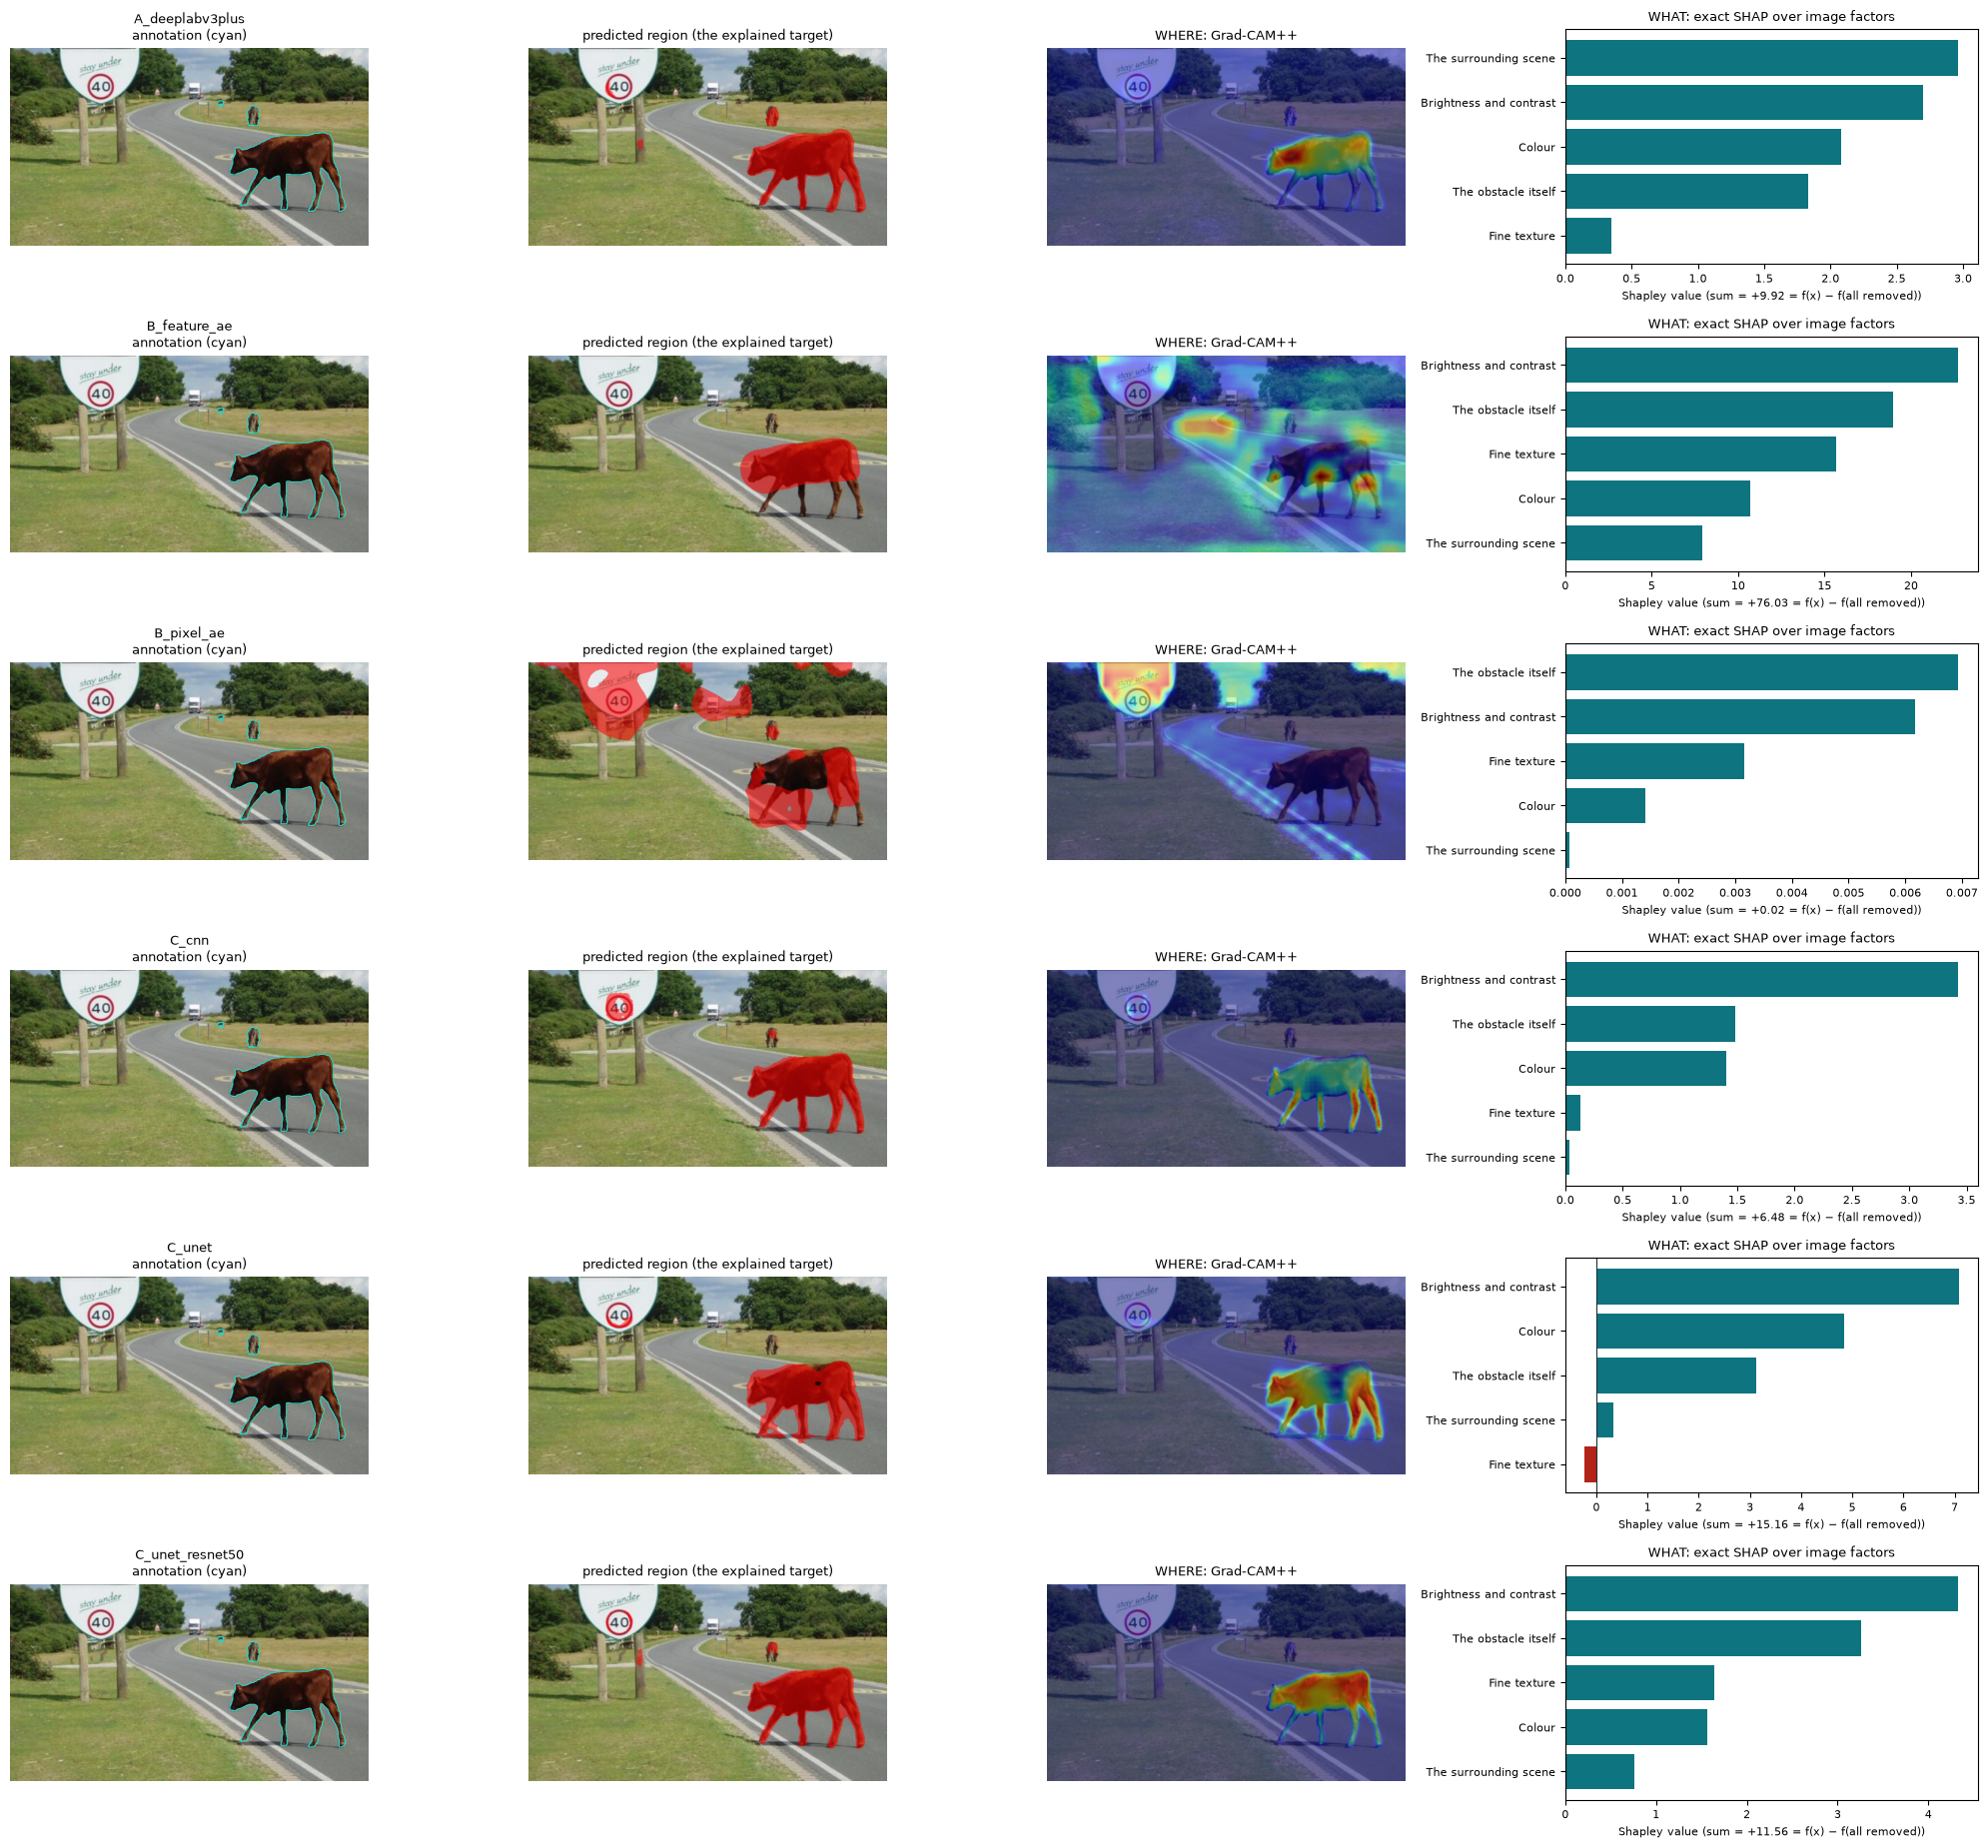

In [3]:
pairs = {(name, idx): xai.explain(p, x_val[idx], method="gradcam++")
         for name, p in predictors.items() for idx in (SUCCESS, FAILURE)}

def shap_bars(ax, what, title):
    """Horizontal bars of the Shapley values, largest magnitude first (teal raises the score, red lowers it)."""
    items = sorted(what["phi"].items(), key=lambda kv: abs(kv[1]))
    values = [v for _, v in items]
    ax.barh([LABELS[k] for k, _ in items], values, color=["#0d7480" if v >= 0 else "#b42318" for v in values])
    ax.axvline(0, color="#1f3038", linewidth=0.8)
    ax.set_title(title, fontsize=9); ax.tick_params(labelsize=8)
    ax.set_xlabel(f"Shapley value (sum = {sum(values):+.2f} = f(x) − f(all removed))", fontsize=8)

def board(idx, path):
    fig, ax = plt.subplots(len(predictors), 4, figsize=(20, 3.1 * len(predictors)), squeeze=False,
                           gridspec_kw={"width_ratios": [1, 1, 1, 1.15]}, tight_layout=True)
    for row, name in enumerate(predictors):
        e = pairs[(name, idx)]
        ax[row, 0].imshow(x_val[idx]); ax[row, 0].contour(gt_val[idx].astype(float), levels=[0.5], colors="#2fd3c4", linewidths=0.8)
        ax[row, 0].set_title(f"{name}\nannotation (cyan)", fontsize=9)
        ax[row, 1].imshow(x_val[idx]); ax[row, 1].imshow(np.ma.masked_where(~e["region"], e["region"]), cmap="autumn", alpha=0.55)
        ax[row, 1].set_title("predicted region (the explained target)", fontsize=9)
        ax[row, 2].imshow(x_val[idx]); ax[row, 2].imshow(e["where"], cmap="jet", alpha=0.45, vmin=0, vmax=1)
        ax[row, 2].set_title("WHERE: Grad-CAM++", fontsize=9)
        for a in ax[row, :3]:
            a.axis("off")
        shap_bars(ax[row, 3], e["what"], "WHAT: exact SHAP over image factors")
    plt.savefig(FIG_DIR / path, dpi=55)
    plt.show()

board(SUCCESS, "6_01_xai_board_success.png")

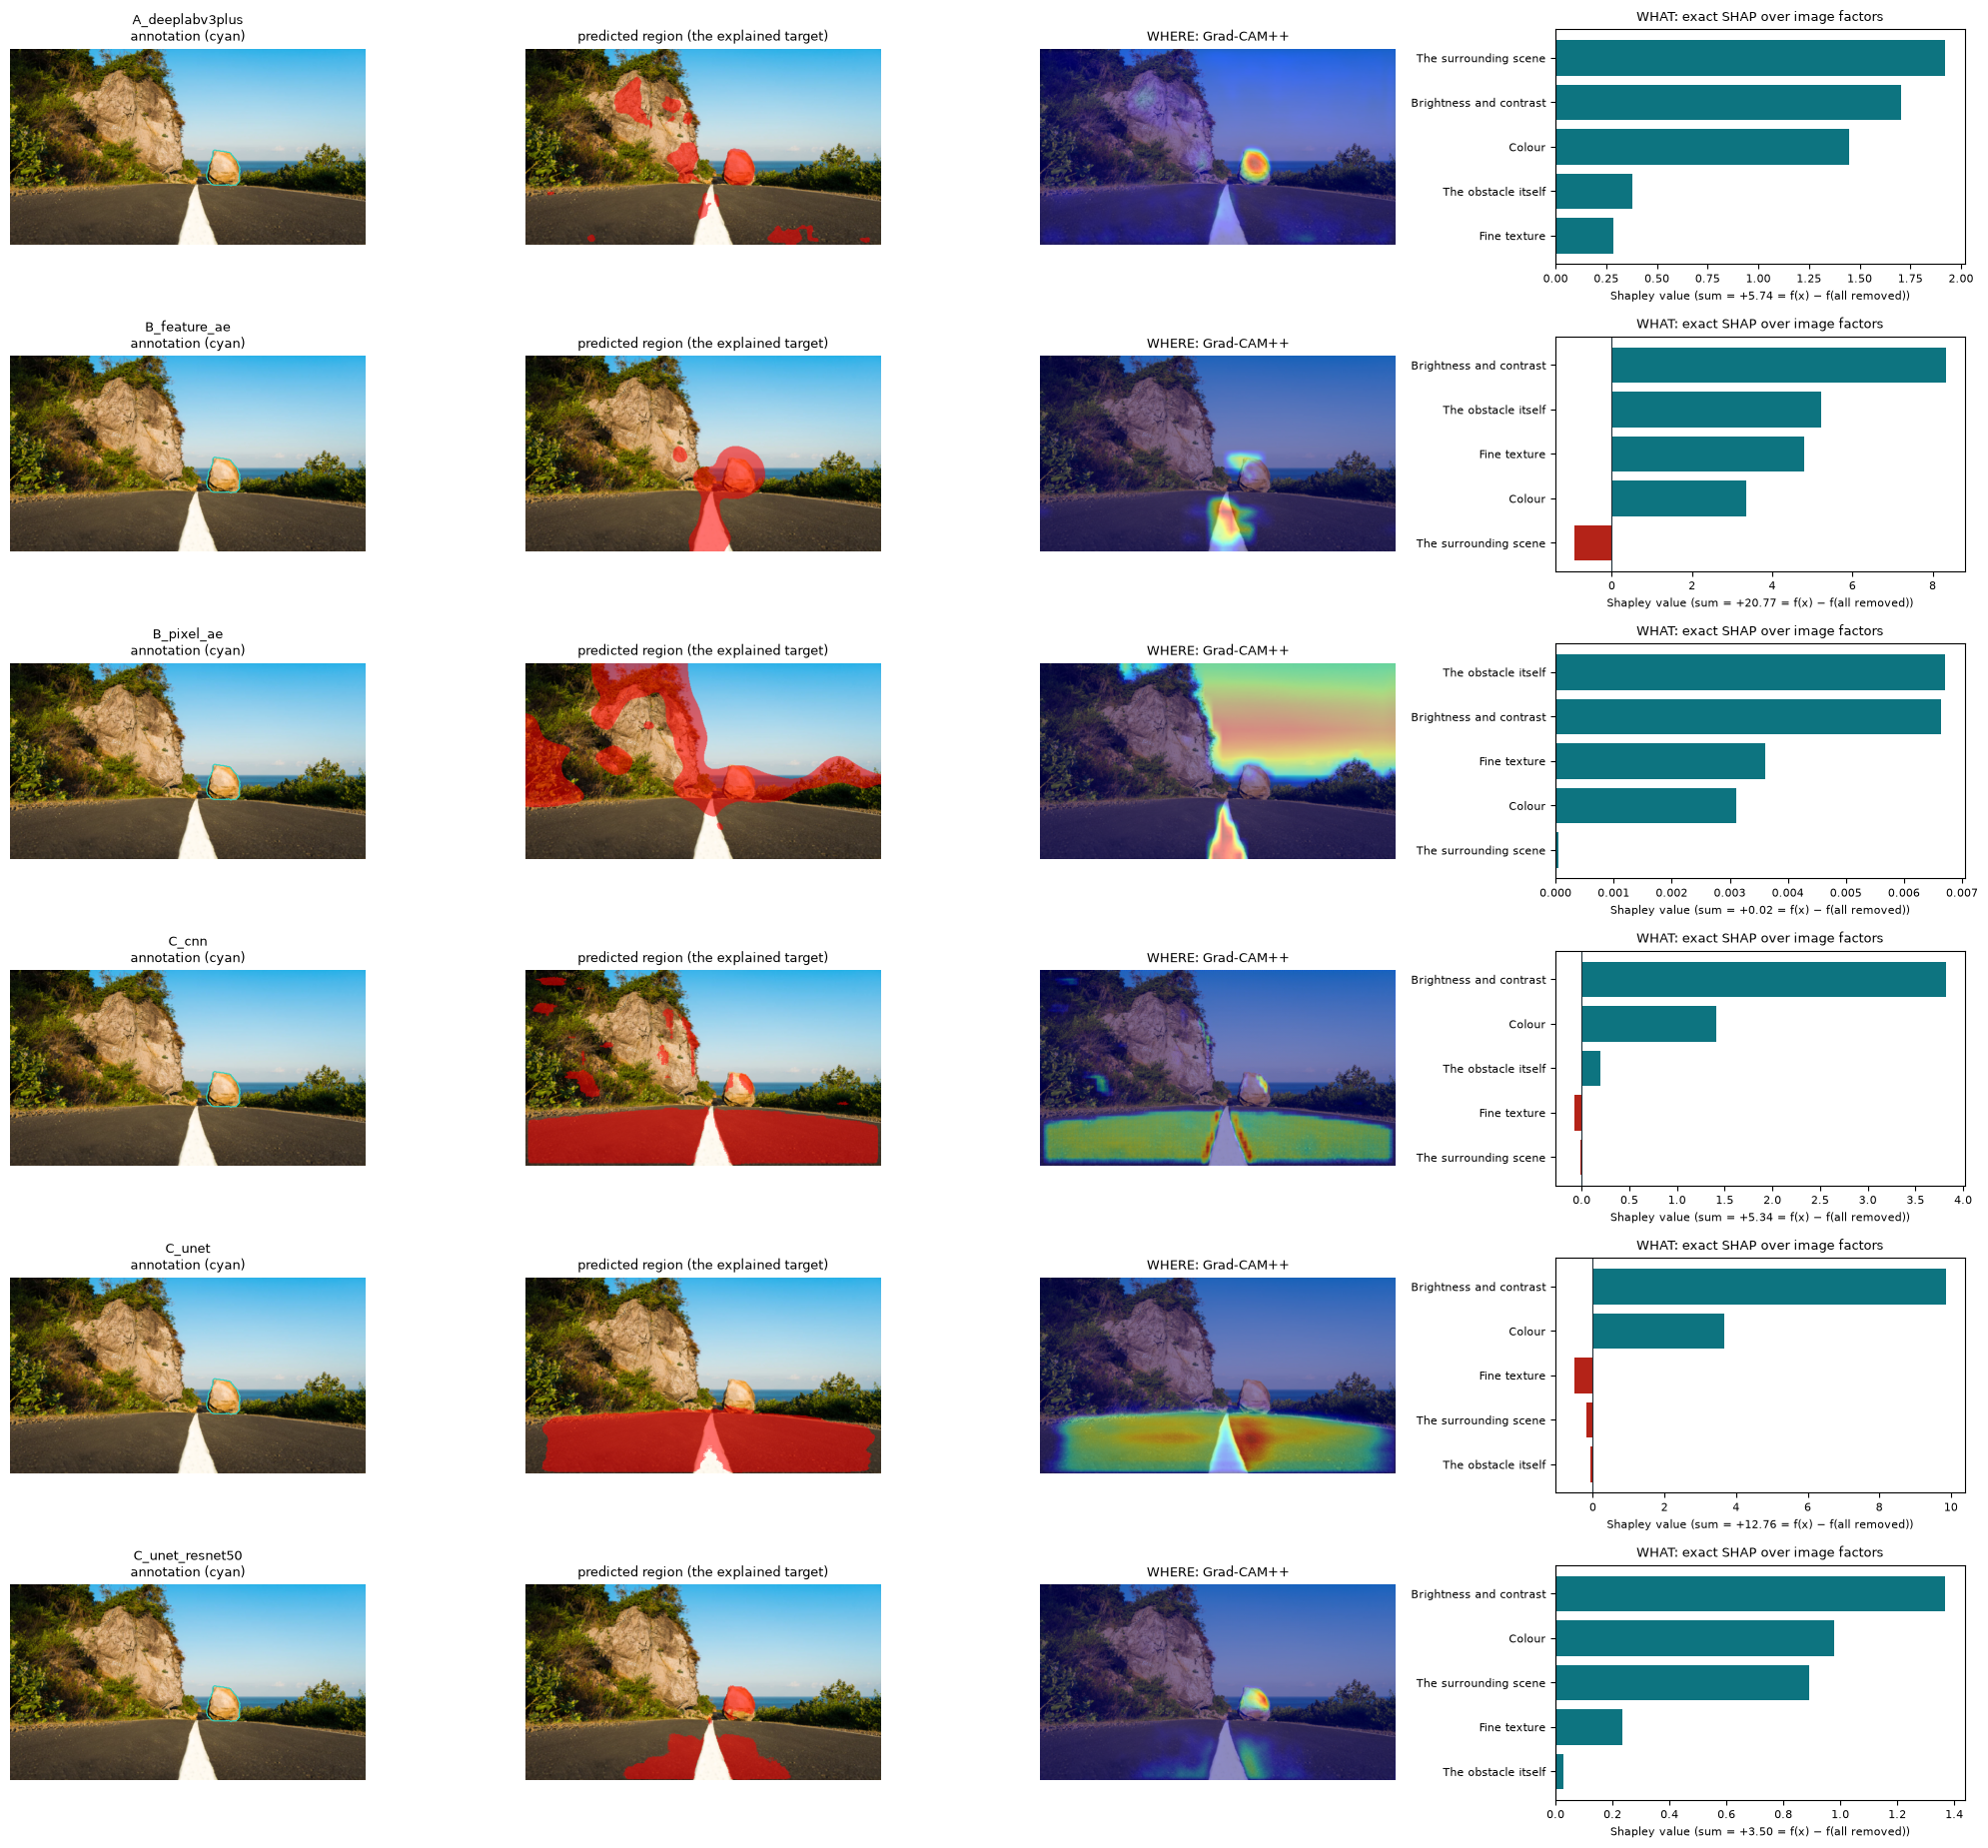

In [4]:
board(FAILURE, "6_02_xai_board_failure.png")

## 3. What each model relies on, over the whole validation split
The Shapley values of one image can depend on that image. Here the "what" is computed for every model on all nine validation photographs, and each factor is reported as its **share of the total attribution** (|φ| divided by the sum of |φ| over the five factors), which removes the different units of logits and reconstruction errors and makes the models comparable. The sign column says whether the factor mostly raises or lowers the score.

In [5]:
rows = []
for name, p in predictors.items():
    for idx in range(len(x_val)):
        region, _ = xai.explanation_region(p, x_val[idx])
        what = pairs[(name, idx)]["what"] if (name, idx) in pairs else xai.factor_shapley(xai.target_score_fn(p, region), x_val[idx], region)
        total = sum(abs(v) for v in what["phi"].values()) or 1.0
        for factor, value in what["phi"].items():
            rows.append({"model": name, "frame": val_frames[idx], "factor": factor, "phi": value,
                         "share": abs(value) / total, "gap": what["efficiency_gap"]})
shap_df = pd.DataFrame(rows)
shares = shap_df.pivot_table(index="model", columns="factor", values="share", aggfunc="mean")[list(FACTORS)]
signs = shap_df.assign(pos=shap_df["phi"] > 0).pivot_table(index="model", columns="factor", values="pos", aggfunc="mean")[list(FACTORS)]
summary = shares.rename(columns=LABELS).round(2)
summary["relies most on"] = shares.idxmax(axis=1).map(LABELS)
summary

factor,Colour,Fine texture,Brightness and contrast,The obstacle itself,The surrounding scene,relies most on
model,,,,,,
A_deeplabv3plus,0.14,0.05,0.30,0.20,0.31,The surrounding scene
B_feature_ae,0.12,0.24,0.37,0.22,0.06,Brightness and contrast
B_pixel_ae,0.07,0.20,0.34,0.38,0.00,The obstacle itself
C_cnn,0.18,0.02,0.63,0.17,0.01,Brightness and contrast
C_unet,0.19,0.05,0.54,0.17,0.05,Brightness and contrast
C_unet_resnet50,0.15,0.14,0.39,0.22,0.11,Brightness and contrast


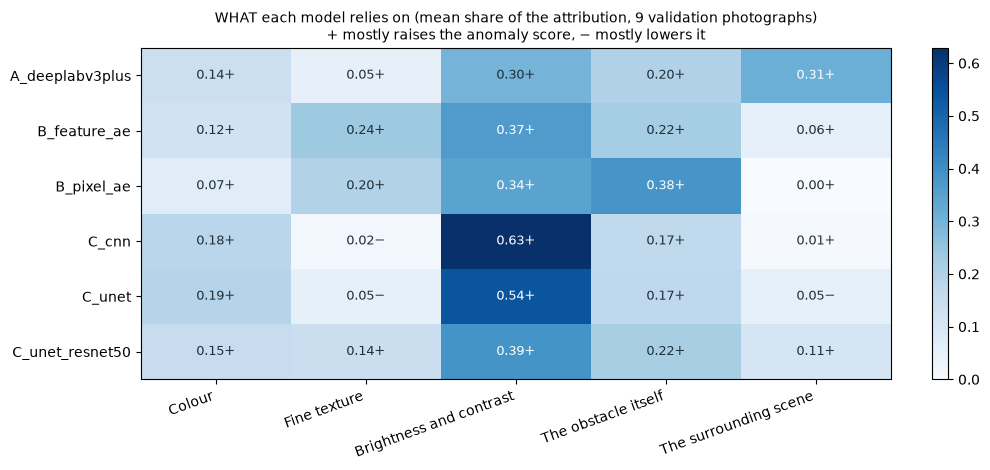

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.8), tight_layout=True)
im = ax.imshow(shares.values, cmap="Blues", vmin=0, vmax=max(0.5, float(shares.values.max())), aspect="auto")
ax.set_xticks(range(len(FACTORS)), [LABELS[f] for f in FACTORS], rotation=20, ha="right")
ax.set_yticks(range(len(shares)), shares.index)
for i in range(shares.shape[0]):
    for j in range(shares.shape[1]):
        sign = "+" if signs.values[i, j] >= 0.5 else "−"
        ax.text(j, i, f"{shares.values[i, j]:.2f}{sign}", ha="center", va="center", fontsize=9,
                color="white" if shares.values[i, j] > 0.3 else "#1f3038")
ax.set_title("WHAT each model relies on (mean share of the attribution, 9 validation photographs)\n+ mostly raises the anomaly score, − mostly lowers it", fontsize=10)
fig.colorbar(im, ax=ax, fraction=0.03)
plt.savefig(FIG_DIR / "6_03_shap_factor_shares.png", dpi=70)
plt.show()

## 4. Segmentation models: which layer supports the prediction?
Grad-CAM++ for the last decoder layer and, for DeepLabV3+, each ASPP branch, on the success case and the same predicted region. Each map is normalised by its own maximum, so the colours compare where a layer looks, not how much it contributes.

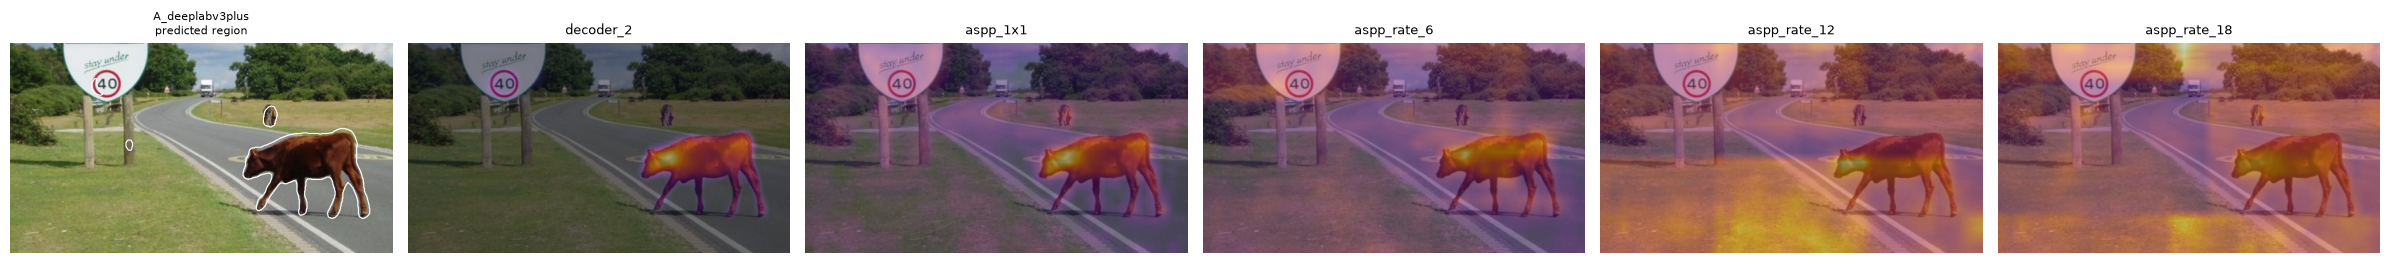

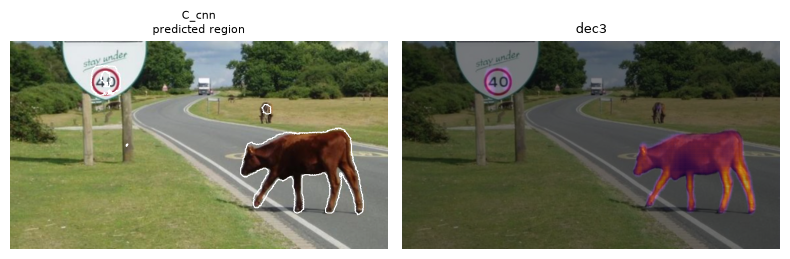

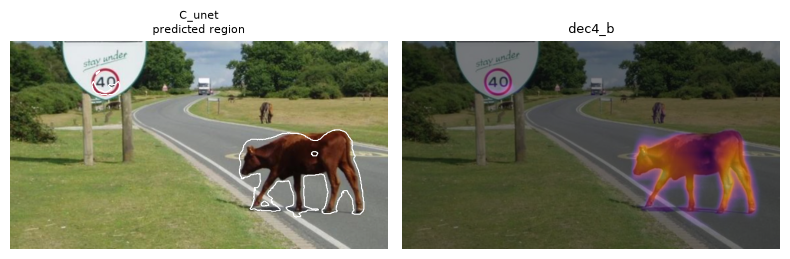

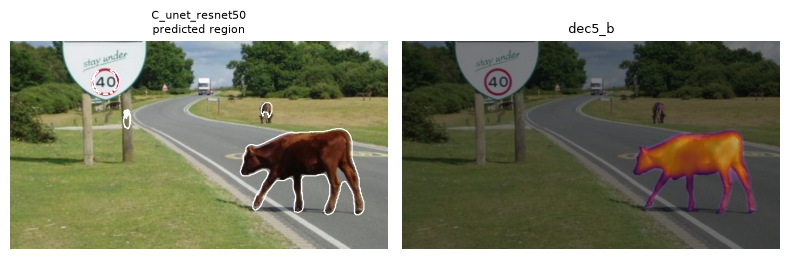

In [7]:
SEG_LAYERS = ["aspp_1x1", "aspp_rate_6", "aspp_rate_12", "aspp_rate_18"]
for name, p in predictors.items():
    if p.model_type != "segmentation":
        continue
    region = pairs[(name, SUCCESS)]["region"]
    names = {layer.name for layer in p.model.layers}
    layers = [xai.default_segmentation_layer(p.model)] + [l for l in SEG_LAYERS if l in names]
    fig, ax = plt.subplots(1, len(layers) + 1, figsize=(4 * (len(layers) + 1), 3), tight_layout=True)
    ax[0].imshow(x_val[SUCCESS]); ax[0].contour(region.astype(float), levels=[0.5], colors="white", linewidths=0.8)
    ax[0].set_title(f"{name}\npredicted region", fontsize=8)
    for a, layer in zip(ax[1:], layers):
        cam, raw_max = xai.grad_cam(p.model, x_val[SUCCESS], layer, xai.logit_target(region),
                                    output_name="anomaly_logits", method="gradcam++")
        a.imshow(x_val[SUCCESS]); a.imshow(cam, cmap="inferno", alpha=0.5, vmin=0, vmax=1)
        a.set_title(layer + (" (zero map)" if raw_max == 0 else ""), fontsize=9)
    for a in ax:
        a.axis("off")
    plt.savefig(FIG_DIR / f"6_04_layers_{name}.png", dpi=60)
    plt.show()

## 5. Is the "where" faithful? Deletion and insertion, Grad-CAM vs Grad-CAM++
For the success case, 32×32 blocks are ranked by the map. **Deletion** replaces the top blocks with a blurred copy of the image; **insertion** restores them on the blurred copy. The tracked value is the same target as above. A faithful map makes deletion fall and insertion rise **faster than random orders** (3 seeds): a lower deletion area and a higher insertion area than random.

In [8]:
faith = []
for name, p in predictors.items():
    region = pairs[(name, SUCCESS)]["region"]
    score = xai.target_score_fn(p, region)
    for method in ("gradcam", "gradcam++"):
        cam, _ = xai.where_map(p, x_val[SUCCESS], region, method)
        r = xai.deletion_insertion(score, x_val[SUCCESS], cam, block=32)
        randoms = [r[k] for k in r if k.startswith("random")]
        rd, ri = np.mean([x["deletion_auc"] for x in randoms]), np.mean([x["insertion_auc"] for x in randoms])
        faith.append({"model": name, "map": method, "deletion (map)": r["attribution"]["deletion_auc"], "deletion (random)": rd,
                      "insertion (map)": r["attribution"]["insertion_auc"], "insertion (random)": ri,
                      "beats random on deletion": r["attribution"]["deletion_auc"] < rd,
                      "beats random on insertion": r["attribution"]["insertion_auc"] > ri})
faith_df = pd.DataFrame(faith)
faith_df.round(3)

,model,map,deletion (map),deletion (random),insertion (map),insertion (random),beats random on deletion,beats random on insertion
0,A_deeplabv3plus,gradcam,4.152,4.946,7.013,4.898,True,True
1,A_deeplabv3plus,gradcam++,4.711,4.946,6.674,4.898,True,True
2,B_feature_ae,gradcam,65.519,31.262,12.170,30.727,False,False
3,B_feature_ae,gradcam++,29.905,31.262,32.107,30.727,True,True
4,B_pixel_ae,gradcam,0.008,0.011,0.012,0.010,True,True
5,B_pixel_ae,gradcam++,0.006,0.011,0.014,0.010,True,True
6,C_cnn,gradcam,0.721,1.382,1.883,1.292,True,True
7,C_cnn,gradcam++,0.712,1.382,1.881,1.292,True,True
8,C_unet,gradcam,10.934,10.751,10.336,10.526,False,False
9,C_unet,gradcam++,10.967,10.751,10.290,10.526,False,False


## 6. Is the "what" exact? The efficiency identity
Because every coalition of factors is evaluated, the Shapley values must add up to f(x) − f(all factors removed) for every model and every image. The largest gap over the 54 explanations of section 3 is printed; anything above float error would mean a bug.

In [9]:
print(f"largest efficiency gap over {shap_df[['model', 'frame']].drop_duplicates().shape[0]} explanations: {shap_df['gap'].max():.2e}")
assert shap_df["gap"].max() < 1e-6

largest efficiency gap over 54 explanations: 1.42e-14


## 7. Save the summary
The factor shares, the faithfulness table and the plain-language reading of each model are written to `reports/results/xai_summary.json`, which the landing page and the report quote.

In [10]:
sentences = {name: xai.describe_what(pairs[(name, SUCCESS)]["what"], name) for name in predictors}
payload = {"cases": {"success": val_frames[SUCCESS], "failure": val_frames[FAILURE]},
           "factors": {f: {"label": LABELS[f], "removal": xai.FACTOR_REMOVAL[f]} for f in FACTORS},
           "shares": shares.round(4).to_dict(orient="index"), "positive_fraction": signs.round(4).to_dict(orient="index"),
           "relies_most_on": shares.idxmax(axis=1).to_dict(), "success_case_sentences": sentences,
           "faithfulness": faith_df.round(4).to_dict(orient="records"),
           "efficiency_gap_max": float(shap_df["gap"].max())}
(RESULTS_DIR / "xai_summary.json").write_text(json.dumps(payload, indent=2, default=float), encoding="utf-8")
for s in sentences.values():
    print("-", s)

- A_deeplabv3plus relies most on the surrounding scene, which raises its anomaly score by 2.96 (30 % of the total attribution), then on brightness and contrast (+2.70).
- B_feature_ae relies most on brightness and contrast, which raises its anomaly score by 22.7 (30 % of the total attribution), then on the obstacle itself (+19.0).
- B_pixel_ae relies most on the obstacle itself, which raises its anomaly score by 0.00694 (39 % of the total attribution), then on brightness and contrast (+0.00616).
- C_cnn relies most on brightness and contrast, which raises its anomaly score by 3.43 (53 % of the total attribution), then on the obstacle itself (+1.48).
- C_unet relies most on brightness and contrast, which raises its anomaly score by 7.09 (45 % of the total attribution), then on colour (+4.85).
- C_unet_resnet50 relies most on brightness and contrast, which raises its anomaly score by 4.33 (37 % of the total attribution), then on the obstacle itself (+3.26).


## 8. Reading the explanations

**Where (Grad-CAM family).**
- On the success case, the maps of DeepLabV3+, the CNN and both U-Nets sit on the cow; the pixel autoencoder's map lands on the sign and the road markings, the high-contrast textures it reconstructs badly, which matches its many false alarms.
- **Grad-CAM++ is the more faithful "where".** Under the deletion / insertion test it beats random orders for five of the six models on both curves. For the feature autoencoder it turns a failing map (plain Grad-CAM: deletion area 65.5 vs 31.3 random, insertion 12.2 vs 30.7) into a passing one (29.9 vs 31.3 and 32.1 vs 30.7). A likely reason: Grad-CAM weights each channel by its mean gradient, and on this model's error map positive and negative gradients can cancel; Grad-CAM++ weights only the positive gradients, pixel by pixel. Grad-CAM++ is therefore the default in the demo and the API.
- The U-Net trained from scratch is the exception: neither method beats random (10.97 vs 10.75 and 10.29 vs 10.53). A likely reason: its evidence is spread over the scene, so no ranking of a few blocks matters more than a random one.

**What (exact SHAP over image factors).** Over the nine validation photographs (section 3):
- **Brightness and contrast** is the largest single factor for four models (from 37 % of the attribution for the feature autoencoder to 63 % for the CNN) and about 30 % or more for every model (just under 30 % for DeepLabV3+); for every model it raises the score on all nine photographs, so flattening the contrast always lowers it. The obstacles of RoadAnomaly (animals, rocks, cones) mostly stand out by contrast against the road.
- **DeepLabV3+ is the only model that relies on the surrounding scene** (31 %, its largest factor): its wide atrous pyramid sees well beyond the obstacle and judges it in its context. A plausible link, not tested here: the same context use may explain some of its false alarms.
- **The pixel autoencoder relies on the obstacle itself** (38 %) and not at all on the scene (0 %), consistent with a model trained on 64-px tiles, whose view of the image is local. The feature autoencoder spreads its attribution over contrast, the obstacle and texture (24 %), the texture weight reflecting its VGG features.
- The supervised models from scratch (CNN, U-Net) depend most on contrast and least on texture (2–5 %); the pretrained U-Net ResNet50 is more balanced (texture 14 %, scene 11 %), closer to how the ImageNet encoders see.
- The Shapley values are exact: the efficiency gap stays below 1e-13 over the 54 explanations (float rounding; section 6 prints the exact value).

**Limits of these explanations.** The factors are removed by chosen transforms (a different blur or contrast level changes the values; the transforms are stated, so the result can be reproduced and challenged). Removing a factor can produce images unlike the training data; Shapley values average over all such combinations but do not remove that effect. Nine validation photographs and one success / failure pair are small samples. These analyses describe the models; none of them was used to choose a model or a threshold.
